# Task-Aware Importance Sampling: oracle and finite-sample risk audit
Two follow-up experiments using the original `Adaptive_VI_Research_Phase2_Complete_Colab.ipynb` synthetic generator, proposal, teacher, features, regression configuration and capped allocator. No VAE training or HMC is needed. Run this standalone notebook from top to bottom; first use `smoke`, then change to `full` and rerun all cells. CPU is sufficient. Full outputs are saved to Google Drive by default and checkpoints resume by dataset. The original confirmation datasets are an audit of prior results, not new independent evidence. The new follow-up datasets (2001–2025) were fixed before evaluation. Both cohorts use predictors reconstructed with the original fixed seed and 512 teacher draws; this is not a claim of byte-identical saved estimators across scikit-learn versions. All uncertainty is conditional on the fitted development predictors.

In [9]:
MODE = "full"  # change to "full" after smoke succeeds
SAVE_TO_DRIVE = True  # False saves to the current Colab session instead

In [10]:
# Follow-up experiments for the original Phase 2 synthetic model.
import os, json, heapq, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp as p2_lse
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display

# MODE and SAVE_TO_DRIVE are set in the notebook configuration cell.
assert MODE in ('smoke','full')
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    root = Path('/content/drive/MyDrive/TaskAware_Synthetic_Oracle_Risk')
else:
    root = Path.cwd() / 'TaskAware_Synthetic_Oracle_Risk'
OUT = root / ('v1_' + MODE)
OUT.mkdir(parents=True, exist_ok=True)
DIMS = (4,8)
COHORTS = {'original_confirmation': list(range(1001,1026)), 'new_followup':list(range(2001,2026))} if MODE=='full' else {'original_confirmation':[1001,1002], 'new_followup':[2001,2002]}
REPS = 16 if MODE=='full' else 2
RISK_REPS = 1024 if MODE=='full' else 16
RISK_PER_DATASET = 12 if MODE=='full' else 3
N = 84; AVG = 48; BUDGET = N*AVG; KMIN=4; KMAX=120; PILOT=8; TEACHER=512
KS=np.arange(KMIN,KMAX+1)
print('Mode:',MODE,'| Results:',OUT,'| Total budget:',BUDGET)
if MODE=='smoke': print('SMOKE TEST ONLY: not scientific evidence.')
(OUT/'config.json').write_text(json.dumps(dict(mode=MODE,cohorts=COHORTS,dimensions=DIMS,reps=REPS,risk_reps=RISK_REPS,risk_per_dataset=RISK_PER_DATASET,n=N,avg=AVG,kmin=KMIN,kmax=KMAX,pilot=PILOT,teacher=TEACHER,dev_seed=742),indent=2))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mode: full | Results: /content/drive/MyDrive/TaskAware_Synthetic_Oracle_Risk/v1_full | Total budget: 4032


904

## 1. Original model and training code
These functions are copied from the original Phase 2 notebook. The data generator and teacher score are unchanged.

In [11]:
def capped_allocate(scores,total,min_k=4,max_k=64):
    scores=np.asarray(scores,dtype=float); B=len(scores)
    assert min_k*B <= total <= max_k*B
    extra=total-B*min_k
    if extra==0: return np.full(B,min_k,dtype=int)
    weights=np.maximum(scores,1e-6)
    # Continuous capped water filling, then largest-remainder integerization.
    lo,hi=0.,max(1.,float(extra)/weights.min())
    for _ in range(45):
        mid=(lo+hi)/2
        if np.minimum(max_k-min_k,mid*weights).sum() < extra: lo=mid
        else: hi=mid
    continuous=np.minimum(max_k-min_k,hi*weights)
    alloc=np.floor(continuous).astype(int)
    remain=int(extra-alloc.sum())
    if remain>0:
        frac=continuous-alloc
        valid=alloc<(max_k-min_k)
        order=np.argsort(-np.where(valid,frac,-np.inf),kind='stable')
        alloc[order[:remain]]+=1
    elif remain<0:
        order=np.argsort(continuous-alloc,kind='stable')
        alloc[order[:(-remain)]]-=1
    out=alloc+min_k
    assert out.sum()==total and out.min()>=min_k and out.max()<=max_k,(out.sum(),total,out.min(),out.max())
    return out

def p2_lpdiag(z,mu,sd):
    return (-0.5*((z-mu)/sd)**2 - np.log(sd) - 0.5*np.log(2*np.pi)).sum(axis=-1)

def p2_make_model(d=4, seed=10, n=84):
    rng=np.random.default_rng(seed)
    c=rng.integers(0,3,n)
    sig=np.array([0.45, 1.0, 2.1])[c]
    means=np.zeros((2,d));means[0,0]=-2.25;means[1,0]=2.25
    modes=rng.choice(2,n,p=[0.55,0.45]);z=rng.normal(size=(n,d))+means[modes]
    x=z+rng.normal(size=(n,d))*sig[:,None]
    return {'d':d,'x':x,'c':c,'sigma':sig,'means':means,'prior_mix':np.array([.55,.45]),'seed':seed}

def p2_truth(m):
    x=m['x'];sig=m['sigma'];means=m['means'];s2=sig[:,None]**2
    lp=np.stack([p2_lpdiag(x,means[j],np.sqrt(1+s2))+np.log(m['prior_mix'][j]) for j in range(2)],axis=1)
    logZ=p2_lse(lp,axis=1)
    resp=np.exp(lp-logZ[:,None]);post_means=(x[:,None,:]+s2[:,None,:]*means[None,:,:])/(1+s2[:,None,:])
    postmu=(resp[:,:,None]*post_means).sum(axis=1)
    return logZ,postmu

def p2_q_params(m):
    x=m['x'];s2=m['sigma']**2
    # Intentionally misspecified unimodal amortized-like proposal in a bimodal model.
    # Larger observation noise can lead to less discriminative mixture responsibilities.
    qmu=(x/(1+s2[:,None]))*.88
    qsd=np.sqrt(s2/(1+s2))*np.array([1.0,1.1,1.25])[m['c']]
    return qmu, qsd[:,None]*np.ones_like(qmu)

def p2_logweight(m,z,qmu,qsd):
    # z: [N,K,d] (or [N,d] after adding axis); includes prior mixture and Gaussian likelihood.
    lp_components=np.stack([p2_lpdiag(z,m['means'][j],np.ones(m['d']))+np.log(m['prior_mix'][j]) for j in range(2)],axis=-1)
    prior=p2_lse(lp_components,axis=-1)
    ll=p2_lpdiag(m['x'][:,None,:],z,m['sigma'][:,None,None])
    proposal=p2_lpdiag(z,qmu[:,None,:],qsd[:,None,:])
    return prior+ll-proposal

def p2_scores(logw,z,shrink=.45,c=None):
    k=logw.shape[1]
    wa=np.exp(logw-p2_lse(logw,axis=1,keepdims=True))
    ess=1/np.sum(wa**2,axis=1)
    ess_score=np.sqrt(np.maximum(0,k/ess-1)+.05)
    mu=np.einsum('nk,nkd->nd',wa,z)
    sqdist=np.sum((z-mu[:,None,:])**2,axis=-1)
    # Plug-in asymptotic SNIS variance for vector posterior mean; finite-pilot and biased.
    raw_tau2=k*np.sum(wa**2*sqdist,axis=1)
    if c is None:pool=np.repeat(np.median(raw_tau2),len(raw_tau2))
    else:pool=np.array([np.median(raw_tau2[c==ci]) for ci in c])
    stabilized=(1-shrink)*raw_tau2+shrink*pool
    task_score=np.sqrt(np.maximum(stabilized,1e-5)+.02)
    return ess_score,task_score,np.sqrt(np.maximum(raw_tau2,1e-6)),ess

def p2_amortized_features(m):
    qmu,qsd=p2_q_params(m)
    x=m['x'];s=m['sigma']
    return np.column_stack([x, x**2, np.linalg.norm(x,axis=1),
        np.linalg.norm(qmu,axis=1),qsd[:,0],s,m['c']])

def p2_offline_teacher(m,K=2048,batch=64,seed=481):
    # No true posterior, exact marginal likelihood or oracle labels are used:
    # pilot-derived SNIS asymptotic-variance proxy, computed offline on development inputs.
    rng=np.random.default_rng(seed)
    n=len(m['x']);tau=np.empty(n);ess=np.empty(n)
    for start in range(0,n,batch):
        keep=np.arange(start,min(n,start+batch))
        sub={**m,'x':m['x'][keep],'c':m['c'][keep], 'sigma':m['sigma'][keep]}
        qm,qs=p2_q_params(sub)
        z=qm[:,None,:]+qs[:,None,:]*rng.normal(size=(len(keep),K,m['d']))
        logw=p2_logweight(sub,z,qm,qs)
        ew,tw,_,es=p2_scores(logw,z,shrink=0,c=None)
        tau[keep]=tw;ess[keep]=ew
    return tau,ess

def p2_build_amortized_predictor(d,seed=742,dev_n=800,dev_k=2048):
    md=p2_make_model(d,seed,n=dev_n)
    teacher,ess=p2_offline_teacher(md,K=dev_k,seed=seed+10)
    features=p2_amortized_features(md)
    # Modest capacity, frozen before any test observations.
    model=HistGradientBoostingRegressor(max_iter=130,max_leaf_nodes=10,l2_regularization=2.0,random_state=seed)
    model.fit(features,np.log(np.maximum(teacher,1e-5)))
    essmodel=HistGradientBoostingRegressor(max_iter=130,max_leaf_nodes=10,l2_regularization=2.0,random_state=seed)
    essmodel.fit(features,np.log(np.maximum(ess,1e-5)))
    online_cost=dev_n*dev_k
    return model,essmodel,online_cost

def p2_eval_amortized(m,score,method,normal,rep,B=48):
    n=len(m['x'])
    qm,qs=p2_q_params(m)
    counts=capped_allocate(np.asarray(score),n*B,min_k=4,max_k=120)
    ids=np.repeat(np.arange(n),counts)
    js=np.concatenate([np.arange(k) for k in counts])
    z=qm[ids]+qs[ids]*normal[ids,js]
    lp=np.stack([p2_lpdiag(z,m['means'][j],np.ones(m['d']))+np.log(m['prior_mix'][j]) for j in range(2)],axis=1)
    lw=p2_lse(lp,axis=1)+p2_lpdiag(m['x'][ids],z,m['sigma'][ids,None])-p2_lpdiag(z,qm[ids],qs[ids])
    estmean=np.empty((n,m['d']));estlogz=np.empty(n);starts=np.r_[0,np.cumsum(counts)[:-1]]
    for i,(st,k) in enumerate(zip(starts,counts)):
        sublw=lw[st:st+k];den=p2_lse(sublw);estmean[i]=np.exp(sublw-den)@z[st:st+k]
        estlogz[i]=den-np.log(k)
    truez,truem=p2_truth(m)
    return {'method':method,'seed':m['seed'],'dimension':m['d'],'trial':rep,
            'posterior_mean_MSE':float(np.mean((estmean-truem)**2)),
            'per_dim_MSE':float(np.mean((estmean-truem)**2)/m['d']),
            'abs_logZ_MAE':float(np.mean(np.abs(estlogz-truez))),
            'evals':n*B}

## 2. Exact asymptotic variance and allocation oracle
For posterior components $p_j=N(a_j,v I)$ and $q=N(b,uI)$, set $A=2/v-1/u$. The ratio $p_jp_k/q$ is an unnormalized Gaussian with precision $AI$ and mean $m_{jk}=[(a_j+a_k)/v-b/u]/A$. Its integral $C_{jk}$ follows by completing the square. Thus
$$\tau_i^2=\sum_{j,k}\gamma_j\gamma_k C_{jk}\left[d/A+\|m_{jk}-\mu_i\|^2\right].$$
The implementation checks $A>0$ for all observations; the original proposal has $u\ge v$, so this holds. The continuous oracle minimizes the asymptotic objective without bounds; the integer oracle allocates each extra sample by the largest marginal decrease $\tau_i^2/[K_i(K_i+1)]$ within 4–120 draws. The same-rule oracle uses the original capped heuristic with exact scores. Neither is a guaranteed finite-sample oracle. All risk values are per coordinate ($\tau_i^2/(dK)$).

In [12]:
# Exact posterior component parameters and variance oracle.
def posterior_components(m):
    s2=m['sigma'][:,None]**2
    x=m['x']; a=m['means']
    lp=np.stack([p2_lpdiag(x,a[j],np.sqrt(1+s2))+np.log(m['prior_mix'][j]) for j in range(2)],axis=1)
    gamma=np.exp(lp-p2_lse(lp,axis=1,keepdims=True))
    means=(x[:,None,:]+s2[:,None,:]*a[None,:,:])/(1+s2[:,None,:])
    v=(s2/(1+s2))[:,0]
    mu=(gamma[:,:,None]*means).sum(axis=1)
    return gamma,means,v,mu

def exact_tau2(m):
    # Integral of p(z|x)^2/q(z|x) times ||z-mu||^2, in closed form.
    # Center coordinates at proposal mean to avoid cancellation.
    gamma,a,v,mu=posterior_components(m)
    qm,qs=p2_q_params(m); u=qs[:,0]**2; d=m['d']
    assert np.allclose(qs,qs[:,0,None])
    A=2/v-1/u
    if not np.all(A>0): raise ValueError('Nonfinite Gaussian product integral: cannot report finite oracle headroom.')
    a=a-qm[:,None,:]; target=mu-qm
    logs=[]
    for j in range(2):
        for k in range(2):
            b=(a[:,j]+a[:,k])/v[:,None]
            mean=b/A[:,None]
            c=(np.sum(a[:,j]**2+a[:,k]**2,axis=1)/v)-np.sum(b*b,axis=1)/A
            logc=-d*np.log(2*np.pi*v)+.5*d*np.log(2*np.pi*u)+.5*d*np.log(2*np.pi/A)-.5*c
            moment=d/A+np.sum((mean-target)**2,axis=1)
            logs.append(np.log(gamma[:,j])+np.log(gamma[:,k])+logc+np.log(moment))
    tau2=np.exp(p2_lse(np.stack(logs,axis=1),axis=1))
    if not np.all(np.isfinite(tau2)&(tau2>0)): raise FloatingPointError('Invalid oracle score')
    post_scale=np.sqrt(d*v+(gamma*np.sum((a-target[:,None,:])**2,axis=2)).sum(axis=1))
    return tau2,post_scale,A

def exact_bounded_oracle(tau2,total=BUDGET):
    # Exact integer optimum for separable convex asymptotic objective.
    k=np.full(len(tau2),KMIN,int)
    h=[(-float(t)/(KMIN*(KMIN+1)),i) for i,t in enumerate(tau2)]
    heapq.heapify(h)
    for _ in range(total-k.sum()):
        _,i=heapq.heappop(h);k[i]+=1
        if k[i]<KMAX: heapq.heappush(h,(-float(tau2[i])/(k[i]*(k[i]+1)),i))
    assert k.sum()==total and k.min()>=KMIN and k.max()<=KMAX
    return k

def allocate(s,total=BUDGET,lo=KMIN,hi=KMAX):
    return capped_allocate(np.asarray(s),total,min_k=lo,max_k=hi)

def bank(m,rng,k):
    qm,qs=p2_q_params(m)
    z=qm[:,None,:]+qs[:,None,:]*rng.normal(size=(len(qm),k,m['d']))
    return z,p2_logweight(m,z,qm,qs)

def evaluate_bank(z,lw,k,truth,logz):
    mask=np.arange(z.shape[1])[None,:]<k[:,None]
    lw=np.where(mask,lw,-np.inf)
    norm=p2_lse(lw,axis=1)
    w=np.exp(lw-norm[:,None]); mu=np.einsum('nk,nkd->nd',w,z)
    return np.mean((mu-truth)**2),np.mean(np.abs(norm-np.log(k)-logz))

def atomic_csv(df,path):
    tmp=path.with_suffix('.tmp');df.to_csv(tmp,index=False);tmp.replace(path)

# Sanity check closed form when q=p (duplicate Gaussian components).
_m=p2_make_model(4,123,n=5);_m['means'][:]=0;_m['x'][:]=0;_m['c'][:]=0;_m['sigma'][:]=.45
_t,_,_=exact_tau2(_m)
assert np.allclose(_t,4*.45**2/(1+.45**2),rtol=1e-10)
print('Analytic oracle q=p identity check passed.')

# Experiment 1: fixed original 512-teacher training and matched budget evaluation.
def run_baselines():
    trial_frames=[]; observation_frames=[]; head_frames=[]
    for d in DIMS:
        with threadpool_limits(limits=2):
            task,ess,cost=p2_build_amortized_predictor(d,seed=742,dev_n=800,dev_k=TEACHER)
        print(f'{d}D: reconstructed original predictors; teacher cost {cost:,}',flush=True)
        for cohort,seeds in COHORTS.items():
            for seed in seeds:
                prefix=OUT/f'{cohort}_d{d}_s{seed}'
                paths=[Path(str(prefix)+suffix) for suffix in ('_trials.csv','_obs.csv','_head.csv')]
                if all(p.exists() for p in paths):
                    tr,ob,he=[pd.read_csv(p) for p in paths]
                else:
                    m=p2_make_model(d,seed,n=N); logz,truth=p2_truth(m)
                    tau2,postscale,precision=exact_tau2(m); tau=np.sqrt(tau2)
                    qm,qs=p2_q_params(m);fs=p2_amortized_features(m)
                    with threadpool_limits(limits=2):
                        ts=np.exp(task.predict(fs)); es=np.exp(ess.predict(fs))
                    scores={'Uniform':np.ones(N),'AmortizedESS':es,'ContextNoise':m['sigma'], 'ProposalWidth':qs[:,0], 'LearnedTask':ts,'PosteriorScaleOracle':postscale,'TauOracleSameRule':tau}
                    counts={name:allocate(s) for name,s in scores.items()}
                    counts['TauOracleOptimalInteger']=exact_bounded_oracle(tau2)
                    unif=tau2.mean()/AVG/d
                    cont=tau.sum()**2/BUDGET/N/d
                    bounded=np.mean(tau2/counts['TauOracleOptimalInteger'])/d
                    he=pd.DataFrame([dict(cohort=cohort,dimension=d,seed=seed,tau_cv=tau.std()/tau.mean(),min_precision=precision.min(),uniform_asymptotic_risk=unif,continuous_oracle_risk=cont,bounded_oracle_risk=bounded,continuous_headroom=1-cont/unif,bounded_headroom=1-bounded/unif,learned_asymptotic_risk=np.mean(tau2/counts['LearnedTask'])/d,learned_asymptotic_capture=(unif-np.mean(tau2/counts['LearnedTask'])/d)/(unif-bounded) if unif>bounded else np.nan)])
                    ob=pd.DataFrame(dict(cohort=cohort,dimension=d,seed=seed,observation=np.arange(N),context=m['c'],context_noise=m['sigma'],proposal_width=qs[:,0],posterior_scale=postscale,tau2=tau2,learned_score=ts,ess_score=es,**{'K_'+name:k for name,k in counts.items()}))
                    rows=[]
                    for rep in range(REPS):
                        # This is the exact original confirmation final random stream.
                        z,lw=bank(m,np.random.default_rng(840000+10000*d+100*seed+rep),KMAX)
                        zp,lp=bank(m,np.random.default_rng(np.random.SeedSequence([80123,d,seed,rep])),PILOT)
                        _,pilot_score,_,_=p2_scores(lp,zp,shrink=0,c=None)
                        # Same plug-in stabilization as original teacher. No fitted model.
                        fresh=allocate(pilot_score,BUDGET-N*PILOT,KMIN,KMAX-PILOT)
                        reuse=allocate(pilot_score,BUDGET,PILOT,KMAX)
                        uniform40=np.full(N,AVG-PILOT,int)
                        def add(name,zz,ll,k,pilot_cost=0,discard=0):
                            assert k.sum()+discard==BUDGET
                            assert (k>=KMIN).all() and (k<=KMAX).all()
                            assert (k+discard//N<=KMAX).all()
                            mse,mae=evaluate_bank(zz,ll,k,truth,logz)
                            rows.append(dict(cohort=cohort,dimension=d,seed=seed,rep=rep,method=name,mse=mse,logZ_mae=mae,total_evals=BUDGET,pilot_evals=pilot_cost,discarded_pilot_evals=discard,mean_final_K=k.mean(),min_final_K=k.min(),max_final_K=k.max()))
                        for name,k in counts.items():add(name,z,lw,k)
                        add('Pilot8Fresh',z,lw,fresh,N*PILOT,N*PILOT)
                        add('Uniform40DiscardPilot',z,lw,uniform40,N*PILOT,N*PILOT)
                        # Reuse pilot samples, acknowledging adaptive stopping can alter bias.
                        zr=np.concatenate([zp,z[:,:KMAX-PILOT]],axis=1);lr=np.concatenate([lp,lw[:,:KMAX-PILOT]],axis=1)
                        add('Pilot8Reuse',zr,lr,reuse,N*PILOT)
                        add('Uniform48ReusePilot',zr,lr,np.full(N,AVG,int),N*PILOT)
                    tr=pd.DataFrame(rows)
                    for df,p in zip((tr,ob,he),paths):atomic_csv(df,p)
                trial_frames.append(tr);observation_frames.append(ob);head_frames.append(he)
            print(f'{d}D {cohort}: {len(seeds)} datasets done',flush=True)
    return tuple(pd.concat(frames,ignore_index=True) for frames in (trial_frames,observation_frames,head_frames))

# Paired analysis: dataset means, not individual Monte Carlo repetitions.
def paired_stats(delta,seed=2022):
    delta=np.asarray(delta,float);n=len(delta);mean=delta.mean()
    half=stats.t.ppf(.975,n-1)*delta.std(ddof=1)/np.sqrt(n) if n>1 else np.nan
    rng=np.random.default_rng(seed)
    if n<=16:
        masks=np.arange(1<<n,dtype=np.uint32)[:,None]; signs=2*((masks>>np.arange(n,dtype=np.uint32))&1).astype(float)-1
        p=np.mean(np.abs(signs@delta/n)>=abs(mean)-1e-14)
    else:
        signs=rng.choice([-1.,1.],size=(50000,n));p=(1+np.sum(np.abs(signs@delta/n)>=abs(mean)-1e-14))/(len(signs)+1)
    return mean,mean-half,mean+half,p,int((delta<0).sum())

def summarize_baselines(tr,he):
    ds=tr.groupby(['cohort','dimension','seed','method'],as_index=False)[['mse','logZ_mae']].mean()
    rows=[]; pair=[]; capture=[]
    for (co,d),g in ds.groupby(['cohort','dimension']):
        pv=g.pivot(index='seed',columns='method',values='mse')
        logp=g.pivot(index='seed',columns='method',values='logZ_mae')
        u=pv.Uniform.mean();o=pv.TauOracleOptimalInteger.mean();l=pv.LearnedTask.mean()
        hh=he[(he.cohort==co)&(he.dimension==d)]
        au=hh.uniform_asymptotic_risk.mean(); ac=hh.continuous_oracle_risk.mean(); ab=hh.bounded_oracle_risk.mean(); al=hh.learned_asymptotic_risk.mean()
        capture.append(dict(cohort=co,dimension=d,n_datasets=len(pv),asymptotic_continuous_headroom_pct=100*(1-ac/au),asymptotic_bounded_headroom_pct=100*(1-ab/au),asymptotic_learned_capture_pct=100*(au-al)/(au-ab) if au>ab else np.nan,median_per_dataset_continuous_headroom_pct=100*hh.continuous_headroom.median(),empirical_tau_oracle_gain_pct=100*(1-o/u),empirical_learned_gain_pct=100*(1-l/u),empirical_capture_relative_to_tau_oracle_pct=100*(u-l)/(u-o) if u>o else np.nan))
        for name in pv.columns:
            v=pv[name];a,b,c,p,w=paired_stats(v-pv.Uniform)
            rows.append(dict(cohort=co,dimension=d,method=name,n_datasets=len(v),mse=v.mean(),gain_pct=100*(1-v.mean()/u),diff_vs_uniform=a,ci_low=b,ci_high=c,signflip_p=p,datasets_lower=w,logZ_mae=logp[name].mean(),logZ_mae_change_pct=100*(logp[name].mean()/logp.Uniform.mean()-1)))
        for base in ['Uniform','AmortizedESS','ContextNoise','ProposalWidth','Pilot8Fresh','Pilot8Reuse','PosteriorScaleOracle','TauOracleSameRule','TauOracleOptimalInteger']:
            a,b,c,p,w=paired_stats(pv.LearnedTask-pv[base]); pair.append(dict(cohort=co,dimension=d,comparison='LearnedTask - '+base,n_datasets=len(pv),difference=a,ci_low=b,ci_high=c,signflip_p=p,datasets_lower=w))
        for first,base in [('Pilot8Fresh','Uniform40DiscardPilot'),('Pilot8Reuse','Uniform48ReusePilot')]:
            a,b,c,p,w=paired_stats(pv[first]-pv[base]);pair.append(dict(cohort=co,dimension=d,comparison=first+' - '+base,n_datasets=len(pv),difference=a,ci_low=b,ci_high=c,signflip_p=p,datasets_lower=w))
    return ds,pd.DataFrame(rows),pd.DataFrame(pair),pd.DataFrame(capture)



Analytic oracle q=p identity check passed.


## 3. Experiment 1 — matched-budget baselines
Every policy spends 4,032 online density evaluations (84 observations × 48). The uniform, learned, ESS, context-noise, proposal-width and oracle methods consume their full allocation as final draws. `Pilot8Fresh` spends 672 draws on independent pilots and 3,360 on fresh final estimates; `Pilot8Reuse` includes the eight pilot draws in the final SNIS estimator (adaptive stopping can change finite-sample bias). Matched pilot controls separate the cost of pilots from their allocation value. Oracle information is free only for diagnostic purposes and is not available to deployable methods. The shared sample bank is a benchmarking convenience; reported costs are per-policy draws consumed, not physical runtime of the whole benchmark.

Headroom and capture are computed separately under the exact asymptotic objective and measured finite-sample MSE. Empirical capture relative to the asymptotic oracle is descriptive, may exceed 100%, and is undefined if the oracle does not improve on uniform. Paired intervals and sign-flip tests use dataset means (not the 16 repetitions as independent units). The principal new comparisons are learned vs context noise, proposal width and the two pilot methods; no tuning on new datasets.

In [13]:
trials, observations, headroom = run_baselines()
seed_means, baseline_summary, paired_comparisons, oracle_summary = summarize_baselines(trials, headroom)
for name,df in [('baseline_trials',trials),('baseline_observations',observations),('oracle_headroom_by_dataset',headroom),('baseline_seed_means',seed_means),('baseline_summary',baseline_summary),('paired_comparisons',paired_comparisons),('oracle_summary',oracle_summary)]:
    atomic_csv(df,OUT/(name+'.csv'))
print('ORACLE HEADROOM: theoretical and measured quantities are separate')
display(oracle_summary.round(5))
print('BASELINE COMPARISON: original and fresh cohorts reported separately')
display(baseline_summary.round(6))
print('PAIRED LEARNED VS BASELINES (negative favors first method)')
display(paired_comparisons.round(6))


4D: reconstructed original predictors; teacher cost 409,600
4D original_confirmation: 25 datasets done
4D new_followup: 25 datasets done
8D: reconstructed original predictors; teacher cost 409,600
8D original_confirmation: 25 datasets done
8D new_followup: 25 datasets done
ORACLE HEADROOM: theoretical and measured quantities are separate


,cohort,dimension,n_datasets,asymptotic_continuous_headroom_pct,asymptotic_bounded_headroom_pct,asymptotic_learned_capture_pct,median_per_dataset_continuous_headroom_pct,empirical_tau_oracle_gain_pct,empirical_learned_gain_pct,empirical_capture_relative_to_tau_oracle_pct
0,new_followup,4,25,9.08507,9.06150,32.72880,8.55867,6.49850,10.45193,160.83592
1,new_followup,8,25,9.57551,9.46474,25.28857,8.56633,5.47693,8.87805,162.09914
2,original_confirmation,4,25,8.39212,8.36588,37.10997,8.14759,6.83829,10.16218,148.60698
3,original_confirmation,8,25,8.48178,8.45304,28.55214,8.35870,5.58982,8.91761,159.53307


BASELINE COMPARISON: original and fresh cohorts reported separately


,cohort,dimension,method,n_datasets,mse,gain_pct,diff_vs_uniform,ci_low,ci_high,signflip_p,datasets_lower,logZ_mae,logZ_mae_change_pct
0,new_followup,4,AmortizedESS,25,0.089098,-3.985684,0.003415,0.002569,0.004261,0.000020,0,0.304506,-0.121725
1,new_followup,4,ContextNoise,25,0.075485,11.901825,-0.010198,-0.011266,-0.009130,0.000020,25,0.330148,8.288776
2,new_followup,4,LearnedTask,25,0.076728,10.451928,-0.008956,-0.009745,-0.008166,0.000020,25,0.312254,2.419516
3,new_followup,4,Pilot8Fresh,25,0.093349,-8.946122,0.007665,0.006313,0.009018,0.000020,0,0.351322,15.233839
4,new_followup,4,Pilot8Reuse,25,0.081316,5.097136,-0.004367,-0.005564,-0.003171,0.000020,24,0.318851,4.583266
5,new_followup,4,PosteriorScaleOracle,25,0.076293,10.959141,-0.009390,-0.010269,-0.008511,0.000020,25,0.315649,3.533057
6,new_followup,4,ProposalWidth,25,0.075876,11.446451,-0.009808,-0.010696,-0.008920,0.000020,25,0.314397,3.122562
7,new_followup,4,TauOracleOptimalInteger,25,0.080115,6.498504,-0.005568,-0.006449,-0.004687,0.000020,25,0.309226,1.426256
8,new_followup,4,TauOracleSameRule,25,0.080247,6.344145,-0.005436,-0.006340,-0.004532,0.000020,25,0.307953,1.008964
9,new_followup,4,Uniform,25,0.085683,0.000000,0.000000,0.000000,0.000000,1.000000,0,0.304877,0.000000


PAIRED LEARNED VS BASELINES (negative favors first method)


,cohort,dimension,comparison,n_datasets,difference,ci_low,ci_high,signflip_p,datasets_lower
0,new_followup,4,LearnedTask - Uniform,25,-0.008956,-0.009745,-0.008166,0.000020,25
1,new_followup,4,LearnedTask - AmortizedESS,25,-0.012371,-0.013417,-0.011324,0.000020,25
2,new_followup,4,LearnedTask - ContextNoise,25,0.001242,0.000668,0.001817,0.000160,5
3,new_followup,4,LearnedTask - ProposalWidth,25,0.000852,0.000538,0.001166,0.000040,3
4,new_followup,4,LearnedTask - Pilot8Fresh,25,-0.016621,-0.017598,-0.015644,0.000020,25
5,new_followup,4,LearnedTask - Pilot8Reuse,25,-0.004588,-0.005333,-0.003844,0.000020,25
6,new_followup,4,LearnedTask - PosteriorScaleOracle,25,0.000435,-0.000010,0.000879,0.055099,10
7,new_followup,4,LearnedTask - TauOracleSameRule,25,-0.003520,-0.004114,-0.002926,0.000020,25
8,new_followup,4,LearnedTask - TauOracleOptimalInteger,25,-0.003387,-0.003924,-0.002851,0.000020,25
9,new_followup,4,Pilot8Fresh - Uniform40DiscardPilot,25,-0.005183,-0.006336,-0.004030,0.000020,24


## 4. Experiment 2 — validate the asymptotic approximation
On each fresh dataset, select 12 observations at random before examining risks (300 observations per dimension in full mode). Generate 1,024 independent SNIS repetitions per observation, reusing prefixes to evaluate every integer K from 4 to 120. The exact posterior mean defines the error; the exact variance oracle supplies the asymptotic prediction. Store Monte Carlo standard errors, the ratio of observed to asymptotic risk, and rank correlation. Prefix comparisons are dependent; the pointwise ratios are descriptive, not independent tests. A ratio near one indicates calibration; a high rank correlation can still support allocation even if the absolute risk curve is poorly calibrated.

In [14]:
# Experiment 2: independent repeated estimates of risk at EVERY integer K in [4,120].
def one_risk_curve(m,i,seed):
    sub={**m,'x':m['x'][i:i+1],'c':m['c'][i:i+1],'sigma':m['sigma'][i:i+1]}
    truth=p2_truth(sub)[1][0]; qm,qs=p2_q_params(sub);d=m['d']
    rng=np.random.default_rng(np.random.SeedSequence([751238,d,seed,i]));sumr=np.zeros(len(KS));sumr2=sumr.copy()
    for start in range(0,RISK_REPS,128):
        r=min(128,RISK_REPS-start)
        z=qm[:,None,:]+qs[:,None,:]*rng.normal(size=(r,KMAX,d))
        lw=p2_logweight(sub,z,qm,qs)
        # Stable prefix SNIS: running maximum and rescaled cumulative numerator/denominator.
        den=np.zeros(r); num=np.zeros((r,d)); mx=np.full(r,-np.inf);errors=[]
        for j in range(KMAX):
            nxt=np.maximum(mx,lw[:,j]); old=np.exp(mx-nxt); new=np.exp(lw[:,j]-nxt)
            den=old*den+new;num=old[:,None]*num+new[:,None]*z[:,j];mx=nxt
            if j+1>=KMIN:errors.append(np.mean((num/den[:,None]-truth)**2,axis=1))
        e=np.stack(errors,axis=1);sumr+=e.sum(axis=0);sumr2+=(e*e).sum(axis=0)
    risk=sumr/RISK_REPS;se=np.sqrt(np.maximum(sumr2-RISK_REPS*risk**2,0)/(RISK_REPS-1)/RISK_REPS)
    return risk,se

def run_risk_curves():
    frames=[]
    # Fixed random subset drawn independently of risk, on fresh follow-up datasets only.
    for d in DIMS:
        for seed in COHORTS['new_followup']:
            path=OUT/f'risk_d{d}_s{seed}.csv'
            if path.exists(): df=pd.read_csv(path)
            else:
                m=p2_make_model(d,seed,n=N);t2,_,_=exact_tau2(m)
                ids=np.sort(np.random.default_rng(np.random.SeedSequence([91911,d,seed])).choice(N,RISK_PER_DATASET,replace=False))
                rows=[]
                for i in ids:
                    risk,se=one_risk_curve(m,int(i),seed);approx=t2[i]/(d*KS)
                    rows.append(pd.DataFrame(dict(dimension=d,seed=seed,observation=i,context=m['c'][i],K=KS,tau2=t2[i],empirical_mse=risk,mc_se=se,asymptotic_mse=approx,ratio=risk/approx)))
                df=pd.concat(rows,ignore_index=True);atomic_csv(df,path)
            frames.append(df)
            print(f'Risk {d}D seed {seed}: {RISK_PER_DATASET} curves',flush=True)
    return pd.concat(frames,ignore_index=True)

def summarize_risk(risk):
    rows=[]
    for (d,k),g in risk.groupby(['dimension','K']):
        ds=g.groupby('seed')[['empirical_mse','asymptotic_mse']].mean()
        rows.append(dict(dimension=d,K=k,n_observations=len(g),n_datasets=len(ds),empirical_mse=ds.empirical_mse.mean(),asymptotic_mse=ds.asymptotic_mse.mean(),ratio_of_means=ds.empirical_mse.mean()/ds.asymptotic_mse.mean(),median_ratio=g.ratio.median(),ratio_p10=g.ratio.quantile(.1),ratio_p90=g.ratio.quantile(.9),spearman_risk_vs_tau2=stats.spearmanr(g.empirical_mse,g.tau2).statistic,fraction_within_20pct=np.mean((g.ratio>=.8)&(g.ratio<=1.2))))
    return pd.DataFrame(rows)


In [15]:
risk_curves=run_risk_curves()
risk_summary=summarize_risk(risk_curves)
atomic_csv(risk_curves,OUT/'finite_sample_risk_per_observation.csv')
atomic_csv(risk_summary,OUT/'finite_sample_risk_summary.csv')
print('FINITE-SAMPLE RISK: selected K values; CSV contains every integer 4–120')
display(risk_summary[risk_summary.K.isin([4,8,16,24,32,48,64,96,120])].round(5))


Risk 4D seed 2001: 12 curves
Risk 4D seed 2002: 12 curves
Risk 4D seed 2003: 12 curves
Risk 4D seed 2004: 12 curves
Risk 4D seed 2005: 12 curves
Risk 4D seed 2006: 12 curves
Risk 4D seed 2007: 12 curves
Risk 4D seed 2008: 12 curves
Risk 4D seed 2009: 12 curves
Risk 4D seed 2010: 12 curves
Risk 4D seed 2011: 12 curves
Risk 4D seed 2012: 12 curves
Risk 4D seed 2013: 12 curves
Risk 4D seed 2014: 12 curves
Risk 4D seed 2015: 12 curves
Risk 4D seed 2016: 12 curves
Risk 4D seed 2017: 12 curves
Risk 4D seed 2018: 12 curves
Risk 4D seed 2019: 12 curves
Risk 4D seed 2020: 12 curves
Risk 4D seed 2021: 12 curves
Risk 4D seed 2022: 12 curves
Risk 4D seed 2023: 12 curves
Risk 4D seed 2024: 12 curves
Risk 4D seed 2025: 12 curves
Risk 8D seed 2001: 12 curves
Risk 8D seed 2002: 12 curves
Risk 8D seed 2003: 12 curves
Risk 8D seed 2004: 12 curves
Risk 8D seed 2005: 12 curves
Risk 8D seed 2006: 12 curves
Risk 8D seed 2007: 12 curves
Risk 8D seed 2008: 12 curves
Risk 8D seed 2009: 12 curves
Risk 8D seed 2

,dimension,K,n_observations,n_datasets,empirical_mse,asymptotic_mse,ratio_of_means,median_ratio,ratio_p10,ratio_p90,spearman_risk_vs_tau2,fraction_within_20pct
0,4,4,300,25,0.45178,1.77039,0.25518,0.27212,0.11345,0.39724,0.78602,0.00000
4,4,8,300,25,0.29878,0.88520,0.33753,0.36631,0.14925,0.51265,0.78214,0.00000
12,4,16,300,25,0.18995,0.44260,0.42916,0.45295,0.19929,0.64001,0.82301,0.00000
20,4,24,300,25,0.14268,0.29507,0.48355,0.51231,0.23244,0.70656,0.83160,0.00333
28,4,32,300,25,0.11575,0.22130,0.52305,0.55657,0.26197,0.74872,0.83636,0.01667
44,4,48,300,25,0.08507,0.14753,0.57660,0.61984,0.30330,0.80553,0.84202,0.11333
60,4,64,300,25,0.06787,0.11065,0.61339,0.66059,0.33644,0.84528,0.84422,0.26333
92,4,96,300,25,0.04900,0.07377,0.66430,0.71345,0.38553,0.89330,0.84744,0.38000
116,4,120,300,25,0.04075,0.05901,0.69053,0.74354,0.42005,0.91587,0.84938,0.43000
117,8,4,300,25,0.37856,1.91161,0.19803,0.24768,0.07574,0.30404,0.78962,0.00000


## 5. Figures and output files

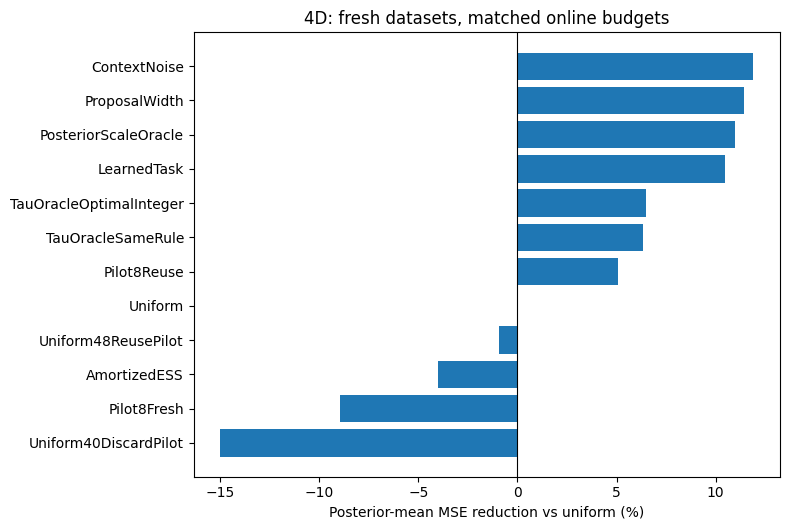

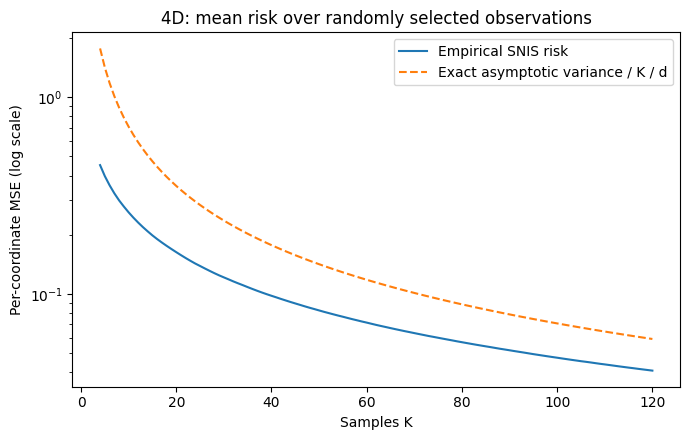

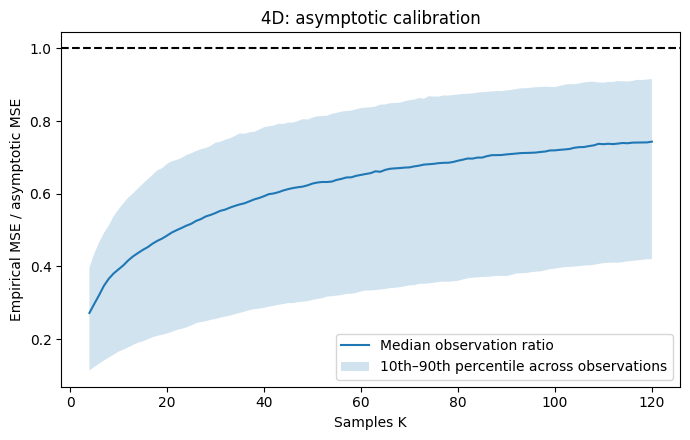

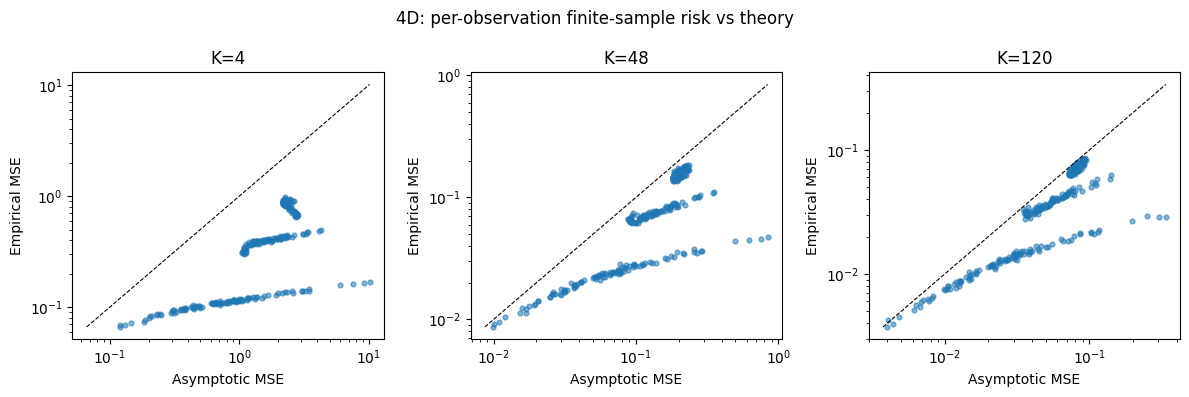

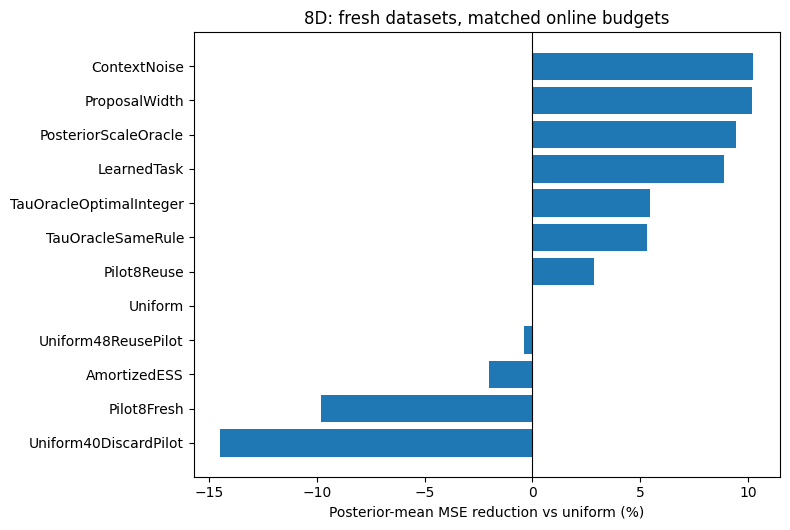

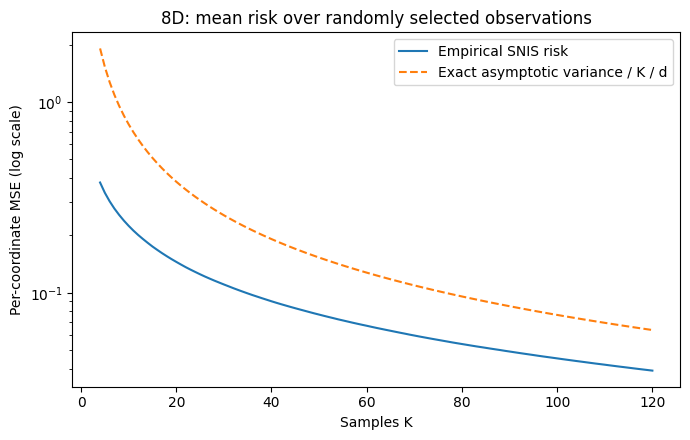

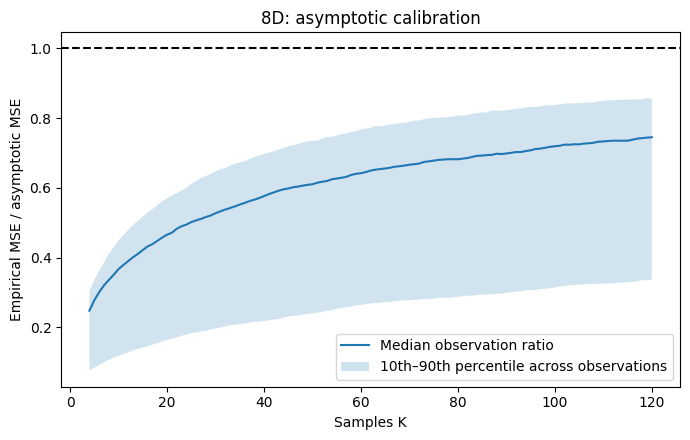

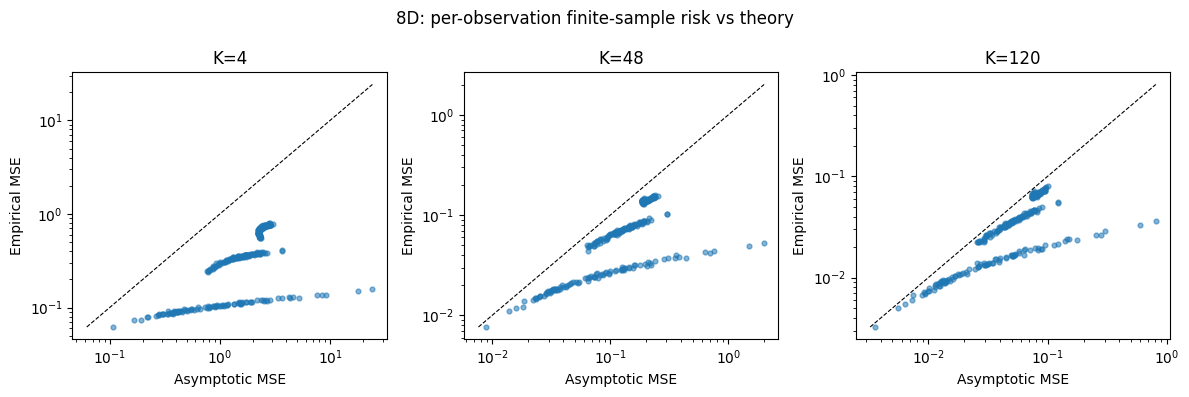

Completed. Results: /content/drive/MyDrive/TaskAware_Synthetic_Oracle_Risk/v1_full


In [16]:
for d in DIMS:
    g=baseline_summary[(baseline_summary.dimension==d)&(baseline_summary.cohort=='new_followup')].sort_values('gain_pct')
    fig,ax=plt.subplots(figsize=(8,5.4));ax.barh(g.method,g.gain_pct);ax.axvline(0,color='black',lw=.8)
    ax.set(xlabel='Posterior-mean MSE reduction vs uniform (%)',title=f'{d}D: fresh datasets, matched online budgets');fig.tight_layout();fig.savefig(OUT/f'baseline_gain_d{d}.png',dpi=180);plt.show();plt.close(fig)
    g=risk_summary[risk_summary.dimension==d]
    fig,ax=plt.subplots(figsize=(7,4.5));ax.plot(g.K,g.empirical_mse,label='Empirical SNIS risk');ax.plot(g.K,g.asymptotic_mse,'--',label='Exact asymptotic variance / K / d');ax.set(yscale='log',xlabel='Samples K',ylabel='Per-coordinate MSE (log scale)',title=f'{d}D: mean risk over randomly selected observations');ax.legend();fig.tight_layout();fig.savefig(OUT/f'risk_curves_d{d}.png',dpi=180);plt.show();plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4.5));ax.plot(g.K,g.median_ratio,label='Median observation ratio');ax.fill_between(g.K.to_numpy(float),g.ratio_p10.to_numpy(float),g.ratio_p90.to_numpy(float),alpha=.2,label='10th–90th percentile across observations');ax.axhline(1,color='black',ls='--');ax.set(xlabel='Samples K',ylabel='Empirical MSE / asymptotic MSE',title=f'{d}D: asymptotic calibration');ax.legend();fig.tight_layout();fig.savefig(OUT/f'risk_calibration_d{d}.png',dpi=180);plt.show();plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(12,4))
    for ax,k in zip(axes,[4,48,120]):
        h=risk_curves[(risk_curves.dimension==d)&(risk_curves.K==k)];a=h.asymptotic_mse.to_numpy();b=h.empirical_mse.to_numpy();lo=min(a.min(),b.min());hi=max(a.max(),b.max());ax.scatter(a,b,s=12,alpha=.55);ax.plot([lo,hi],[lo,hi],'k--',lw=.8);ax.set(xscale='log',yscale='log',xlabel='Asymptotic MSE',ylabel='Empirical MSE',title=f'K={k}')
    fig.suptitle(f'{d}D: per-observation finite-sample risk vs theory');fig.tight_layout();fig.savefig(OUT/f'risk_scatter_d{d}.png',dpi=180);plt.show();plt.close(fig)
print('Completed. Results:',OUT)
